In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sn
import nltk

In [3]:
nltk.download('vader_lexicon')

[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


True

In [4]:
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [5]:
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [6]:
# from google.colab import files
# uploaded = files.upload()

In [7]:
# from google.colab import drive
# drive.mount('/content/drive/', force_remount = True)

In [8]:
path =  "/content/drive/MyDrive/chatgpt_reviews.csv"

Read the file and inspect the data

In [9]:
df = pd.read_csv('/content/drive/MyDrive/chatgpt_reviews.csv')
df

,Review Id,Review,Ratings,Review Date
0,6fb93778-651a-4ad1-b5ed-67dd0bd35aac,good,5,2024-08-23 19:30:05
1,81caeefd-3a28-4601-a898-72897ac906f5,good,5,2024-08-23 19:28:18
2,452af49e-1d8b-4b68-b1ac-a94c64cb1dd5,nice app,5,2024-08-23 19:22:59
3,372a4096-ee6a-4b94-b046-cef0b646c965,"nice, ig",5,2024-08-23 19:20:50
4,b0d66a4b-9bde-4b7c-8b11-66ed6ccdd7da,"this is a great app, the bot is so accurate to...",5,2024-08-23 19:20:39
...,...,...,...,...
196722,462686ff-e500-413c-a6b4-2badc2e3b21d,Update 2023,5,2023-07-27 16:26:31
196723,f10e0d48-ecb6-42db-b103-46c0046f9be9,its grear,5,2023-09-23 16:25:18
196724,df909a49-90b5-4dac-9b89-c4bd5a7c2f75,Funtastic App,5,2023-11-08 13:57:14
196725,abe43878-973f-4e96-a765-c4af5c7f7b20,hi all,5,2023-07-25 15:32:57


In [10]:
print("shaped : ",df.shape)
print("df Column : ",df.shape[1])
print("df Row : ",df.shape[0])


shaped :  (196727, 4)
df Column :  4
df Row :  196727


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 196727 entries, 0 to 196726
Data columns (total 4 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   Review Id    196727 non-null  object
 1   Review       196721 non-null  object
 2   Ratings      196727 non-null  int64 
 3   Review Date  196727 non-null  object
dtypes: int64(1), object(3)
memory usage: 6.0+ MB


In [12]:
df.describe()

,Ratings
count,196727.000000
mean,4.503535
std,1.083004
min,1.000000
25%,5.000000
50%,5.000000
75%,5.000000
max,5.000000


**Data Cleaing**

In [13]:

# standardising the columns

df.columns = df.columns.str.strip().str.lower().str.replace(" ","_")

df['review_id'] = df['review_id'].str.strip()
df['review'] = df['review'].str.strip()

df.head()



,review_id,review,ratings,review_date
0,6fb93778-651a-4ad1-b5ed-67dd0bd35aac,good,5,2024-08-23 19:30:05
1,81caeefd-3a28-4601-a898-72897ac906f5,good,5,2024-08-23 19:28:18
2,452af49e-1d8b-4b68-b1ac-a94c64cb1dd5,nice app,5,2024-08-23 19:22:59
3,372a4096-ee6a-4b94-b046-cef0b646c965,"nice, ig",5,2024-08-23 19:20:50
4,b0d66a4b-9bde-4b7c-8b11-66ed6ccdd7da,"this is a great app, the bot is so accurate to...",5,2024-08-23 19:20:39


In [14]:
#changing data type
df['review_date'] = df['review_date'].astype('datetime64[ns]')


In [15]:
#handling missing values
inspect_null = df.isna().sum()
print(inspect_null)


print(df[df['review'].isna() == True])


review_id      0
review         6
ratings        0
review_date    0
dtype: int64
                                   review_id review  ratings  \
35896   6d2f3aaa-babf-4105-9743-fa31462a526d    NaN        1   
49374   a6fc983e-8729-4d78-8cdf-25a47194932d    NaN        1   
155476  ffc32dd8-45b3-44a0-b8cf-8bd83ec5a621    NaN        1   
162561  527e0514-b444-4c59-b0a9-7f7774335ece    NaN        5   
169011  a16c4191-19e8-4cc2-b072-0118fae7b5f4    NaN        5   
169192  4c07a17f-5c2a-489b-8136-49fae85a6cfa    NaN        5   

               review_date  
35896  2024-07-11 18:15:05  
49374  2024-06-24 06:20:22  
155476 2024-04-25 06:07:13  
162561 2024-04-04 18:56:52  
169011 2024-03-23 23:03:54  
169192 2024-03-29 13:52:29  


In [16]:
df.loc[(df['review'].isna()) & (df['ratings'] < 2),'review'] = 'Bad Experiance'
df.loc[(df['review'].isna()) & ((df['ratings'] >= 2) & (df['ratings']< 3.5)),'review'] = 'Average  Experiance'
df.loc[(df['review'].isna()) & (df['ratings'] >= 3.5),'review'] = 'Good  Experiance'



In [17]:
df[df['review'] =='Good  Experiance']

,review_id,review,ratings,review_date
162561,527e0514-b444-4c59-b0a9-7f7774335ece,Good Experiance,5,2024-04-04 18:56:52
169011,a16c4191-19e8-4cc2-b072-0118fae7b5f4,Good Experiance,5,2024-03-23 23:03:54
169192,4c07a17f-5c2a-489b-8136-49fae85a6cfa,Good Experiance,5,2024-03-29 13:52:29


In [18]:
# drop duplicates
df[df.duplicated()].sort_values(by='review_id')

df.duplicated().sum()

df_cleaned = df.drop_duplicates().copy()
print(df.duplicated().sum())


2511


**Data Transformation**

In [19]:
#add columns

#add user_group
condition = [df_cleaned['ratings'] < 2,df_cleaned['ratings'].between(2,3.5),df_cleaned['ratings'] > 3.5]

arguments = ['Negative Review','Neutral Review','Positive Review']

df_cleaned['review_type'] = np.select(condition,arguments,default = 'unknown')


**Exploratory Data Analysis**

In [20]:
df_cleaned.describe(include = 'all')

,review_id,review,ratings,review_date,review_type
count,194216,194216,194216.000000,194216,194216
unique,193154,125497,NaN,NaN,3
top,4299411b-fb16-4785-970f-b57ebb484857,good,NaN,NaN,Positive Review
freq,9,7609,NaN,NaN,170858
mean,NaN,NaN,4.502631,2024-03-25 06:32:37.295047936,NaN
min,NaN,NaN,1.000000,2023-07-25 15:01:35,NaN
25%,NaN,NaN,5.000000,2024-01-04 09:09:33,NaN
50%,NaN,NaN,5.000000,2024-04-21 09:48:35.500000,NaN
75%,NaN,NaN,5.000000,2024-06-26 14:20:45,NaN
max,NaN,NaN,5.000000,2024-08-23 19:30:05,NaN


<Axes: xlabel='ratings'>

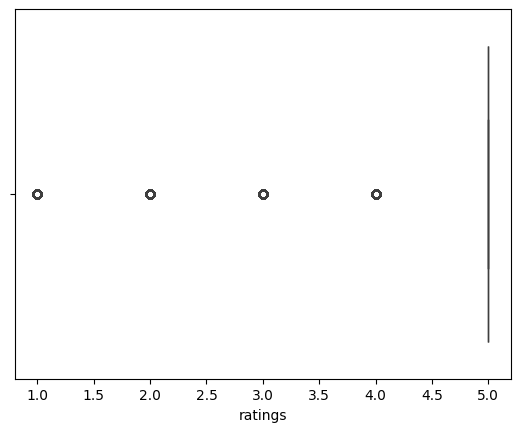

In [21]:
sn.boxplot(x=df_cleaned['ratings'],orient = 'h')

<BarContainer object of 3 artists>

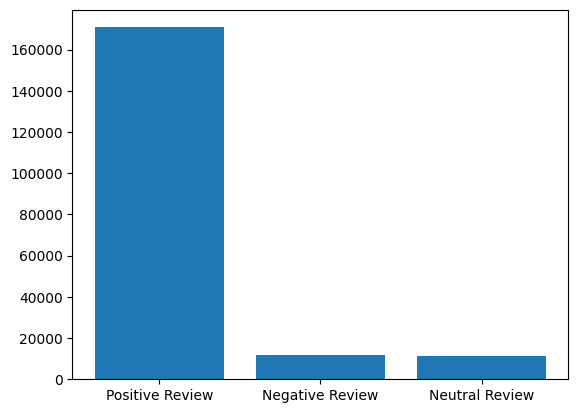

In [22]:
ratings_group = df_cleaned['review_type'].value_counts().reset_index(name = 'Count')
ratings_group

plt.bar(ratings_group['review_type'],ratings_group['Count'])


In [23]:
from nltk.sentiment import SentimentIntensityAnalyzer
sia = SentimentIntensityAnalyzer()

In [24]:
df_cleaned['sentiment_score'] = df_cleaned['review'].apply(lambda x : sia.polarity_scores(str(x))['compound'])
df_cleaned

,review_id,review,ratings,review_date,review_type,sentiment_score
0,6fb93778-651a-4ad1-b5ed-67dd0bd35aac,good,5,2024-08-23 19:30:05,Positive Review,0.4404
1,81caeefd-3a28-4601-a898-72897ac906f5,good,5,2024-08-23 19:28:18,Positive Review,0.4404
2,452af49e-1d8b-4b68-b1ac-a94c64cb1dd5,nice app,5,2024-08-23 19:22:59,Positive Review,0.4215
3,372a4096-ee6a-4b94-b046-cef0b646c965,"nice, ig",5,2024-08-23 19:20:50,Positive Review,0.4215
4,b0d66a4b-9bde-4b7c-8b11-66ed6ccdd7da,"this is a great app, the bot is so accurate to...",5,2024-08-23 19:20:39,Positive Review,0.9427
...,...,...,...,...,...,...
196722,462686ff-e500-413c-a6b4-2badc2e3b21d,Update 2023,5,2023-07-27 16:26:31,Positive Review,0.0000
196723,f10e0d48-ecb6-42db-b103-46c0046f9be9,its grear,5,2023-09-23 16:25:18,Positive Review,0.0000
196724,df909a49-90b5-4dac-9b89-c4bd5a7c2f75,Funtastic App,5,2023-11-08 13:57:14,Positive Review,0.0000
196725,abe43878-973f-4e96-a765-c4af5c7f7b20,hi all,5,2023-07-25 15:32:57,Positive Review,0.0000


In [25]:
df_cleaned['sentiment'] = np.where(df_cleaned['sentiment_score'] >= 0.05,'Positive',np.where(df_cleaned['sentiment_score'] <= -0.05, 'Negative', 'Neutral'))
df_cleaned.head(20)

,review_id,review,ratings,review_date,review_type,sentiment_score,sentiment
0,6fb93778-651a-4ad1-b5ed-67dd0bd35aac,good,5,2024-08-23 19:30:05,Positive Review,0.4404,Positive
1,81caeefd-3a28-4601-a898-72897ac906f5,good,5,2024-08-23 19:28:18,Positive Review,0.4404,Positive
2,452af49e-1d8b-4b68-b1ac-a94c64cb1dd5,nice app,5,2024-08-23 19:22:59,Positive Review,0.4215,Positive
3,372a4096-ee6a-4b94-b046-cef0b646c965,"nice, ig",5,2024-08-23 19:20:50,Positive Review,0.4215,Positive
4,b0d66a4b-9bde-4b7c-8b11-66ed6ccdd7da,"this is a great app, the bot is so accurate to...",5,2024-08-23 19:20:39,Positive Review,0.9427,Positive
5,9cdc3f78-15cd-4e9d-9287-31bc5af496c4,so nice app,5,2024-08-23 19:18:35,Positive Review,0.4754,Positive
6,3c26ee92-4d72-45ee-9242-caab930903ca,"just love this app, or guy",4,2024-08-23 19:14:40,Positive Review,0.6369,Positive
7,f293ed19-688a-42e2-8282-ddd077771a94,great app,1,2024-08-23 19:12:00,Negative Review,0.6249,Positive
8,99af016c-6db2-4f24-9952-cb3bece40be8,Very impressive,5,2024-08-23 19:11:46,Positive Review,0.5563,Positive
9,27dd6ea5-ada3-4795-a297-6faa7d4b6ba2,helps with coding a lot this ai is great for e...,5,2024-08-23 19:11:09,Positive Review,0.7717,Positive


<BarContainer object of 3 artists>

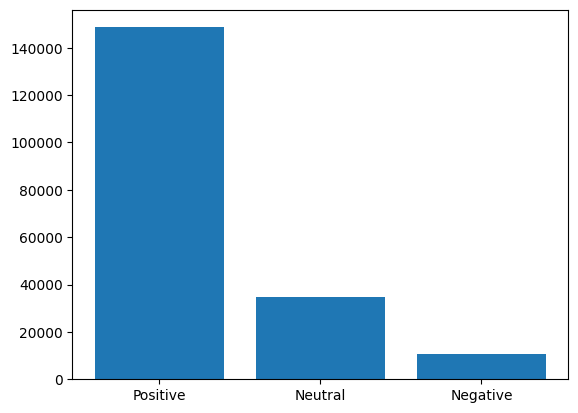

In [26]:
sentiment_group = df_cleaned['sentiment'].value_counts().reset_index(name = 'Count')
sentiment_group
plt.bar(sentiment_group['sentiment'],sentiment_group['Count'])

In [27]:
negative_review = df_cleaned[df_cleaned['sentiment'] == 'Negative'].copy()
negative_review.shape

(10698, 7)

In [28]:
from nltk import word_tokenize

negative_review['tokens'] = negative_review['review'].apply(lambda x : word_tokenize(str(x).lower()))

negative_review

,review_id,review,ratings,review_date,review_type,sentiment_score,sentiment,tokens
10,17769ae4-51f6-439c-af12-f59d242e1f6b,I am not very happy with this because chatgpt ...,3,2024-08-23 19:09:14,Neutral Review,-0.9370,Negative,"[i, am, not, very, happy, with, this, because,..."
16,ebe189d2-27e0-4779-bb71-ca243512ac2b,It used to be good but now the app keeps sayin...,3,2024-08-23 19:02:28,Neutral Review,-0.3818,Negative,"[it, used, to, be, good, but, now, the, app, k..."
97,bc72b0b6-bf71-41e2-9fd2-c4a40eb89cc4,nothing can be better than this in the new gen...,5,2024-08-23 17:14:19,Positive Review,-0.3412,Negative,"[nothing, can, be, better, than, this, in, the..."
98,ad660376-1173-4009-88c1-681830d33d53,has a lot of complains,2,2024-08-23 17:09:34,Neutral Review,-0.3818,Negative,"[has, a, lot, of, complains]"
108,9e91cd96-78bb-49ef-aa80-c2ac3827f9b1,good but not best,3,2024-08-23 16:51:52,Neutral Review,-0.5577,Negative,"[good, but, not, best]"
...,...,...,...,...,...,...,...,...
196665,2085e4bf-b5ec-4015-91ea-e825e8272464,Not sure,5,2024-04-24 17:22:58,Positive Review,-0.2411,Negative,"[not, sure]"
196667,97c239b1-e331-46b6-a5d2-7eb2ea67662e,Sin palabras,5,2023-08-02 00:40:56,Positive Review,-0.5574,Negative,"[sin, palabras]"
196668,0d82515c-8a3f-4fca-94fc-c833961d40b5,Idk man,5,2023-07-26 12:02:33,Positive Review,-0.1027,Negative,"[idk, man]"
196690,8f9b55f4-e525-4c17-90eb-31804ed84e6b,No Bueno,5,2024-01-19 02:16:08,Positive Review,-0.2960,Negative,"[no, bueno]"


In [29]:
from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))

negative_review['clean_tokens'] = negative_review['tokens'].apply(
    lambda words: [
        word for word in words
        if word.isalpha() and word not in stop_words
    ]
)

negative_review

,review_id,review,ratings,review_date,review_type,sentiment_score,sentiment,tokens,clean_tokens
10,17769ae4-51f6-439c-af12-f59d242e1f6b,I am not very happy with this because chatgpt ...,3,2024-08-23 19:09:14,Neutral Review,-0.9370,Negative,"[i, am, not, very, happy, with, this, because,...","[happy, chatgpt, answers, questions, ask, stop..."
16,ebe189d2-27e0-4779-bb71-ca243512ac2b,It used to be good but now the app keeps sayin...,3,2024-08-23 19:02:28,Neutral Review,-0.3818,Negative,"[it, used, to, be, good, but, now, the, app, k...","[used, good, app, keeps, saying, error, occure..."
97,bc72b0b6-bf71-41e2-9fd2-c4a40eb89cc4,nothing can be better than this in the new gen...,5,2024-08-23 17:14:19,Positive Review,-0.3412,Negative,"[nothing, can, be, better, than, this, in, the...","[nothing, better, new, generation]"
98,ad660376-1173-4009-88c1-681830d33d53,has a lot of complains,2,2024-08-23 17:09:34,Neutral Review,-0.3818,Negative,"[has, a, lot, of, complains]","[lot, complains]"
108,9e91cd96-78bb-49ef-aa80-c2ac3827f9b1,good but not best,3,2024-08-23 16:51:52,Neutral Review,-0.5577,Negative,"[good, but, not, best]","[good, best]"
...,...,...,...,...,...,...,...,...,...
196665,2085e4bf-b5ec-4015-91ea-e825e8272464,Not sure,5,2024-04-24 17:22:58,Positive Review,-0.2411,Negative,"[not, sure]",[sure]
196667,97c239b1-e331-46b6-a5d2-7eb2ea67662e,Sin palabras,5,2023-08-02 00:40:56,Positive Review,-0.5574,Negative,"[sin, palabras]","[sin, palabras]"
196668,0d82515c-8a3f-4fca-94fc-c833961d40b5,Idk man,5,2023-07-26 12:02:33,Positive Review,-0.1027,Negative,"[idk, man]","[idk, man]"
196690,8f9b55f4-e525-4c17-90eb-31804ed84e6b,No Bueno,5,2024-01-19 02:16:08,Positive Review,-0.2960,Negative,"[no, bueno]",[bueno]


In [30]:
from nltk import FreqDist

all_words = [
    word
    for words in negative_review['clean_tokens']
    for word in words
]

freq = FreqDist(all_words)

freq.most_common(15)

[('app', 3331),
 ('good', 1150),
 ('wrong', 1025),
 ('error', 913),
 ('chatgpt', 911),
 ('ca', 879),
 ('ai', 876),
 ('bad', 870),
 ('problem', 865),
 ('use', 821),
 ('time', 794),
 ('even', 732),
 ('answer', 709),
 ('chat', 703),
 ('like', 639)]

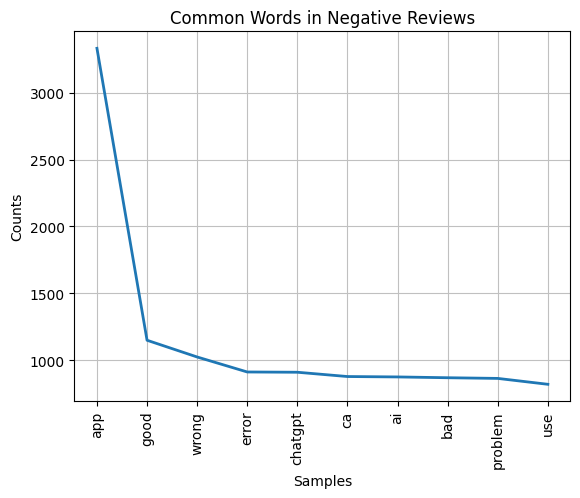

In [31]:
freq.plot(10, title='Common Words in Negative Reviews')
plt.show()

<Axes: xlabel='date', ylabel='count'>

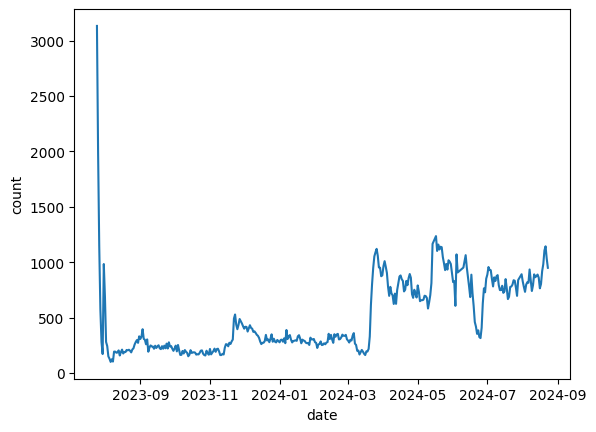

In [32]:
df_cleaned['date']= df_cleaned['review_date'].dt.normalize()
df_cleaned


user_count_by_date = df_cleaned.groupby('date')['review_id'].count().reset_index(name = 'count')

user_count_by_date

sn.lineplot(data = user_count_by_date, x = 'date',y = 'count')